In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

sns.set_theme(style="whitegrid")

# Cargar datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test_nolabel.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("Dimensiones (filas, columnas)")
print(f"  train             : {train.shape}")
print(f"  test_nolabel      : {test.shape}")
print(f"  sample_submission : {sample_sub.shape}")

Dimensiones (filas, columnas)
  train             : (36188, 22)
  test_nolabel      : (5000, 21)
  sample_submission : (5000, 2)


In [ ]:
print("train.head")
display(train.head())

train.head


,Id,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,Expected
0,44dc8df9,35,admin.,married,high.school,unknown,no,no,telephone,jul,fri,189,1,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,0
1,3f62aa06,52,technician,married,basic.9y,no,no,no,telephone,jun,fri,188,1,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,0
2,34bd6148,44,blue-collar,single,basic.9y,no,no,no,cellular,may,mon,267,4,999,1,failure,-1.8,92.893,-46.2,1.244,5099.1,0
3,e1671cba,35,admin.,married,high.school,no,yes,yes,telephone,jun,fri,14,9,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,0
4,c20477f0,33,technician,married,university.degree,no,yes,no,cellular,jul,thu,52,7,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,0


In [ ]:

print("Columnas de train:", list(train.columns))
print("Columnas de test:", list(test.columns))
print("Columnas de submission:", list(sample_sub.columns))


assert set(train.drop(columns="Expected").columns) == set(test.columns)

Columnas de train: ['Id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'Expected']
Columnas de test: ['Id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Columnas de submission: ['Id', 'Predicted']


## 1. Conocimiento del dominio

El objetivo (`Expected`) indica si el cliente contrata un depósito a plazo (1) o no (0). Es un problema de clasificación binaria muy desbalanceado (11,23 % de positivos), por lo que usamos Macro F1 como métrica de referencia

Grupos de variables
- Cliente: `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`.
- Contacto actual: `contact`, `month`, `day_of_week`, `duration`, `campaign`.
- Historial: `pdays`, `previous`, `poutcome`.
- Contexto macroeconómico: `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`.

Hipótesis previas (qué esperamos que prediga bien)
1. `poutcome` y `pdays`: quien aceptó una campaña anterior es el candidato más probable a aceptar otra vez.
2. Contexto macro (sobre todo `euribor3m`): con tipos bajos los depósitos son menos atractivos y la gente reacciona distinto. Esperamos señal fuerte, pero con variables muy correlacionadas entre sí (redundancia).
3. `contact`: la llamada a móvil debería funcionar mejor que la fija.
4. `job` y `age`: estudiantes y jubilados suelen ser más receptivos al ahorro.
5. `month`: puede haber estacionalidad de la campaña.
6. `default`, `housing`, `loan`: un cliente con impagos o con préstamos tiene menos capacidad de ahorro.
7. `duration`: se espera que sea la variable más predictiva, pero no es utilizable: solo se conoce *después* de la llamada y, si ya sabes lo que ha durado, ya sabes casi el resultado (fuga de información). La excluimos del modelo.
8. `Id` no aporta información: se descarta.

In [ ]:
print("Tipos de datos (train)")
print(train.dtypes)
print("info de train")
train.info()

Tipos de datos (train)
Id                    str
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
Expected            int64
dtype: object
info de train
<class 'pandas.DataFrame'>
RangeIndex: 36188 entries, 0 to 36187
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              36188 non-null  str    
 1   age             36188 non-null  int64  
 2   job             36188 non-null  str    
 3   marital         36188 non-null  str    
 4   educ

In [ ]:
experiment_log = pd.DataFrame(columns=[ #dataframe con datos obtenidos de los algoritmos
    "id", "algoritmo", "modificaciones", "hiperparametros",
    "macro_f1_val", "macro_f1_cv", "conclusiones"
])

def log_experiment(exp_id, algoritmo, modificaciones, hiperparametros,
                   macro_f1_val=None, macro_f1_cv=None, conclusiones=""):
    global experiment_log
    experiment_log.loc[len(experiment_log)] = [
        exp_id, algoritmo, modificaciones, hiperparametros,
        macro_f1_val, macro_f1_cv, conclusiones
    ]

In [ ]:
print("Distribución de Expected")
print(train["Expected"].value_counts())
print(train["Expected"].value_counts(normalize=True).round(4))

Distribución de Expected
Expected
0    32125
1     4063
Name: count, dtype: int64
Expected
0    0.8877
1    0.1123
Name: proportion, dtype: float64


## 2. Análisis exploratorio

### 2.1 Calidad de los datos y estadísticos descriptivos

In [ ]:
TARGET, ID_COL = "Expected", "Id"
FEATURES = [c for c in train.columns if c not in (TARGET, ID_COL)]
num_cols = train[FEATURES].select_dtypes(include="number").columns.tolist()
cat_cols = train[FEATURES].select_dtypes(exclude="number").columns.tolist()

print("Numéricas :", num_cols)
print("Categóricas:", cat_cols)

# Nulos reales y 'unknown' (en %), train vs test
def calidad(df, nombre):
    out = pd.DataFrame({
        "nulos_%": df[FEATURES].isna().mean() * 100,
        "unknown_%": (df[FEATURES] == "unknown").mean() * 100,
    }).round(2)
    out.columns = [f"{c}_{nombre}" for c in out.columns]
    return out

tabla_calidad = pd.concat([calidad(train, "train"), calidad(test, "test")], axis=1)
print(" Nulos y 'unknown' (%)")
display(tabla_calidad[(tabla_calidad > 0).any(axis=1)])

# Duplicados (sin contar el Id)
print("\nFilas duplicadas en train (sin Id):",
      train.drop(columns=[ID_COL]).duplicated().sum())
print("Duplicados con target contradictorio:",
      train.drop(columns=[ID_COL, TARGET]).duplicated(keep=False).sum()
      - train.drop(columns=[ID_COL]).duplicated(keep=False).sum())

# Estadísticas descriptivas numéricas
print("Descriptivas numéricas")
display(train[num_cols].describe().T.round(3))

# Frecuencias de categóricas
for c in cat_cols:
    print(f"\n--- {c} ---")
    print(train[c].value_counts(dropna=False).to_frame("n")
          .assign(pct=lambda d: (d["n"] / len(train) * 100).round(2)))

# pdays == 999 frente a poutcome y previous
print("pdays == 999 ")
print("% de filas con pdays==999:", round((train["pdays"] == 999).mean() * 100, 2))
print(pd.crosstab(train["pdays"] == 999, train["poutcome"], margins=True))
print("\nprevious cuando pdays==999:")
print(train.loc[train["pdays"] == 999, "previous"].value_counts().head())

Numéricas : ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
 Nulos y 'unknown' (%)


,nulos_%_train,unknown_%_train,nulos_%_test,unknown_%_test
job,0.0,0.78,0.0,0.94
marital,0.0,0.19,0.0,0.22
education,0.0,4.19,0.0,4.32
default,0.0,20.93,0.0,20.48
housing,0.0,2.42,0.0,2.28
loan,0.0,2.42,0.0,2.28



Filas duplicadas en train (sin Id): 9
Duplicados con target contradictorio: 0
Descriptivas numéricas


,count,mean,std,min,25%,50%,75%,max
age,36188.0,40.035,10.444,17.000,32.000,38.000,47.000,98.000
duration,36188.0,258.104,258.898,0.000,102.000,179.000,319.000,4918.000
campaign,36188.0,2.580,2.804,1.000,1.000,2.000,3.000,56.000
pdays,36188.0,962.341,187.240,0.000,999.000,999.000,999.000,999.000
previous,36188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,36188.0,0.082,1.569,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,36188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,36188.0,-40.508,4.618,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,36188.0,3.622,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,36188.0,5167.016,72.266,4963.600,5099.100,5191.000,5228.100,5228.100



--- job ---
                  n    pct
job                       
admin.         9131  25.23
blue-collar    8129  22.46
technician     5920  16.36
services       3509   9.70
management     2576   7.12
retired        1542   4.26
entrepreneur   1292   3.57
self-employed  1242   3.43
housemaid       928   2.56
unemployed      870   2.40
student         766   2.12
unknown         283   0.78

--- marital ---
              n    pct
marital               
married   21908  60.54
single    10172  28.11
divorced   4039  11.16
unknown      69   0.19

--- education ---
                         n    pct
education                        
university.degree    10699  29.57
high.school           8384  23.17
basic.9y              5292  14.62
professional.course   4598  12.71
basic.4y              3679  10.17
basic.6y              2007   5.55
unknown               1515   4.19
illiterate              14   0.04

--- default ---
             n    pct
default              
no       28612  79.06
unknown   75

### Conclusiones sobre calidad de datos
- No hay nulos reales, pero sí valores `unknown`: `default` (20,9 %), `education` (4,2 %), `housing`/`loan` (2,4 %, siempre en las mismas filas), `job` (0,8 %) y `marital` (0,2 %). Train y test tienen proporciones casi idénticas.
- Hay 9 filas duplicadas sin contradicciones de etiqueta, así que no afectan.
- `pdays = 999` (96,3 % de las filas) no es una distancia real sino un código para "nunca contactado". Coincide exactamente con `poutcome = nonexistent` más los fallos. Tratarlo como número sería un error.
- `duration` y `campaign` tienen colas largas (máximo 4918 s y 56 llamadas). `duration` se excluye por fuga de información; a `campaign` se le aplica `log1p` en los modelos basados en distancia (KNN).

### 2.2 Relación de las variables con el objetivo: contraste de hipótesis

housing y loan son 'unknown' en las mismas filas: True

=== previous según pdays==999 y poutcome ===
pdays      False           True             
poutcome failure success failure nonexistent
previous                                    
0              0       0       0       31227
1              0     764    3268           0
2             77     281     304           0
3             33     112      39           0
4             17      32      12           0
5              1      14       1           0
6              0       4       1           0
7              0       1       0           0

=== Tasa de éxito por (pdays==999, poutcome) ===


n  tasa_exito
pdays poutcome                      
False failure        128      0.5000
      success       1208      0.6490
True  failure       3625      0.1330
      nonexistent  31227      0.0875


--- job (tasa global = 0.1123) ---


,n,tasa_exito
job,,
student,766,0.3081
retired,1542,0.2529
unemployed,870,0.1379
admin.,9131,0.1293
unknown,283,0.1131
management,2576,0.1122
technician,5920,0.1083
housemaid,928,0.1034
self-employed,1242,0.1023



--- marital (tasa global = 0.1123) ---


,n,tasa_exito
marital,,
unknown,69,0.1594
single,10172,0.1392
divorced,4039,0.1035
married,21908,0.1012


... (12 outputs left out)


--- day_of_week (tasa global = 0.1123) ---


,n,tasa_exito
day_of_week,,
thu,7584,0.1210
tue,7091,0.1180
wed,7129,0.1164
fri,6912,0.1069
mon,7472,0.0989



--- poutcome (tasa global = 0.1123) ---


,n,tasa_exito
poutcome,,
success,1208,0.6490
failure,3753,0.1455
nonexistent,31227,0.0875


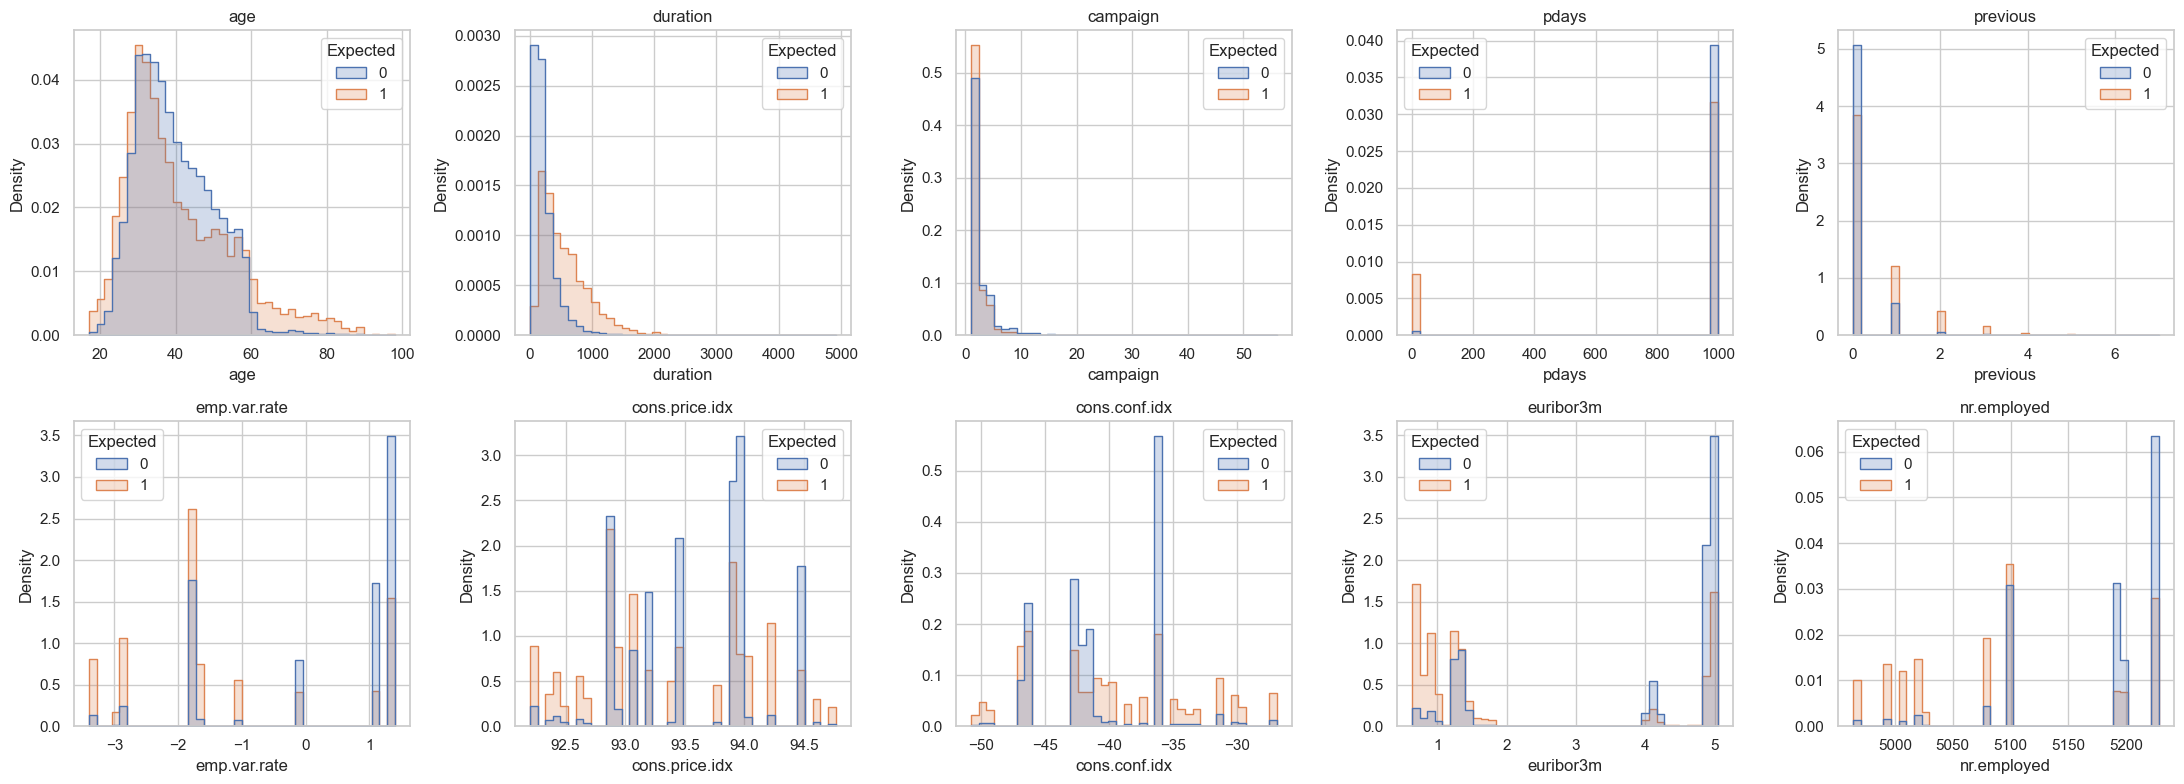

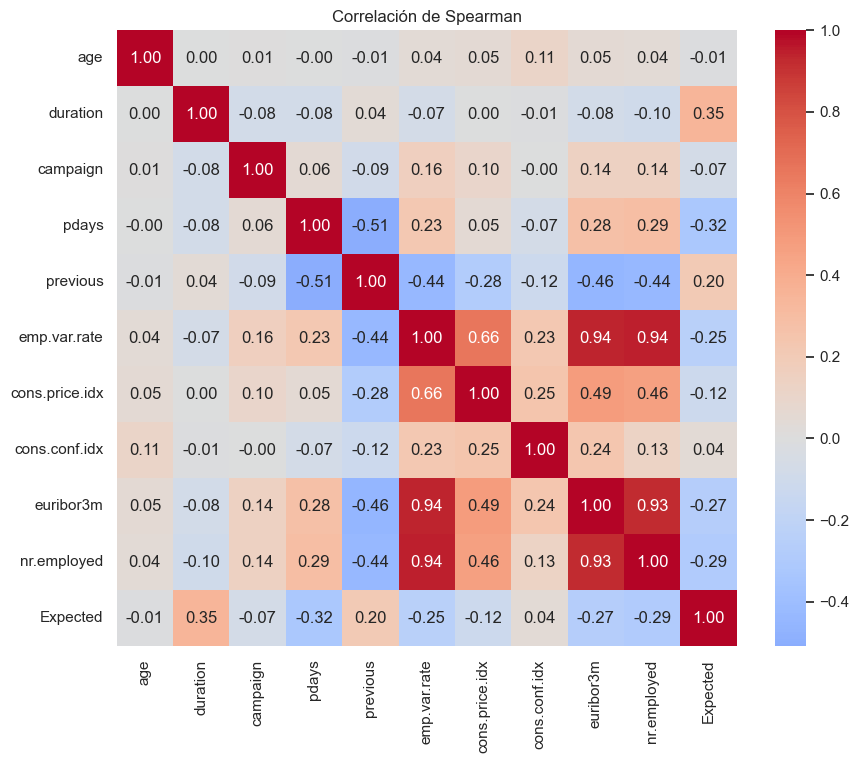


Correlación con el target:
duration          0.348
pdays            -0.324
nr.employed      -0.286
euribor3m        -0.268
emp.var.rate     -0.248
previous          0.204
cons.price.idx   -0.119
campaign         -0.067
cons.conf.idx     0.041
age              -0.011
Name: Expected, dtype: float64

=== duration por clase ===


,count,mean,std,min,25%,50%,75%,max
Expected,,,,,,,,
0,32125.0,220.7,206.5,0.0,95.0,163.0,278.0,4918.0
1,4063.0,553.9,401.8,37.0,253.0,449.0,743.5,4199.0


Filas con duration == 0: 4 | tasa de éxito: 0.0

=== KS train vs test (numéricas) ===


,estadistico,p_valor
age,0.0063,0.9941
duration,0.0112,0.6332
campaign,0.0115,0.6066
pdays,0.0013,1.0000
previous,0.0043,1.0000
emp.var.rate,0.0080,0.9373
cons.price.idx,0.0077,0.9567
cons.conf.idx,0.0115,0.5995
euribor3m,0.0129,0.4571
nr.employed,0.0080,0.9373



=== Categorías presentes solo en train o solo en test ===
default -> solo train: {'yes'} | solo test: set()
(si no se imprime nada, los conjuntos de categorías coinciden)

=== Mes: % en train vs test ===


,train,test
month,,
may,0.3351,0.3282
jul,0.1747,0.1704
aug,0.1492,0.1556
jun,0.1289,0.1304
nov,0.1002,0.0948
apr,0.0629,0.0710
oct,0.0174,0.0180
sep,0.0137,0.0148
mar,0.0132,0.0134


In [ ]:
# 2.2 · Relación de las variables con el objetivo
from scipy.stats import ks_2samp

# 0. Verificaciones pendientes
print("housing y loan son 'unknown' en las mismas filas:",
      ((train["housing"] == "unknown") == (train["loan"] == "unknown")).all())

print("\n=== previous según pdays==999 y poutcome ===")
print(pd.crosstab(train["previous"], [train["pdays"] == 999, train["poutcome"]]))

print("\n=== Tasa de éxito por (pdays==999, poutcome) ===")
display(train.groupby([train["pdays"] == 999, "poutcome"])[TARGET]
        .agg(n="size", tasa_exito="mean").round(4))

# 1. Tasa de éxito por categoría (incluye 'unknown' como categoría)
for c in cat_cols:
    t = (train.groupby(c)[TARGET].agg(n="size", tasa_exito="mean")
         .sort_values("tasa_exito", ascending=False).round(4))
    print(f"\n--- {c} (tasa global = {train[TARGET].mean():.4f}) ---")
    display(t)

# 2. Distribución de las numéricas por clase
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=train, x=c, hue=TARGET, bins=40, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# 3. Correlaciones (Spearman, más robusta a asimetrías)
corr = train[num_cols + [TARGET]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación de Spearman")
plt.show()
print("\nCorrelación con el target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

# 4. duration: solo para justificar su exclusión
print("\n=== duration por clase ===")
display(train.groupby(TARGET)["duration"].describe().round(1))
print("Filas con duration == 0:", (train["duration"] == 0).sum(),
      "| tasa de éxito:", train.loc[train["duration"] == 0, TARGET].mean())

# 5. Train vs test: ¿hay desplazamiento de distribución?
print("\n=== KS train vs test (numéricas) ===")
ks = pd.DataFrame({c: ks_2samp(train[c], test[c]) for c in num_cols},
                  index=["estadistico", "p_valor"]).T.round(4)
display(ks)

print("\n=== Categorías presentes solo en train o solo en test ===")
for c in cat_cols:
    s_tr, s_te = set(train[c]), set(test[c])
    if s_tr != s_te:
        print(c, "-> solo train:", s_tr - s_te, "| solo test:", s_te - s_tr)
print("(si no se imprime nada, los conjuntos de categorías coinciden)")

print("\n=== Mes: % en train vs test ===")
display(pd.concat([train["month"].value_counts(normalize=True).rename("train"),
                   test["month"].value_counts(normalize=True).rename("test")],
                  axis=1).round(4))

### Conclusiones del análisis exploratorio

**Contraste de las hipótesis iniciales**

### Análisis de las hipótesis iniciales

| # | Hipótesis | Resultado | Evidencia |
|---|---|---|---|
| 1 | `poutcome` y `pdays` son buenos predictores | Confirmada | Los clientes con una campaña anterior exitosa tienen una tasa de contratación del 64,9 %, frente al 11,2 % global. Además, haber tenido contacto previo aumenta considerablemente la probabilidad de contratación. |
| 2 | El contexto macroeconómico influye en la contratación | Confirmada, pero en sentido contrario al esperado | `nr.employed`, `euribor3m` y `emp.var.rate` presentan correlaciones negativas importantes. Los tipos de interés bajos coinciden con mayores tasas de contratación, posiblemente por campañas mejor dirigidas. |
| 3 | El móvil funciona mejor que el fijo | Confirmada | Las llamadas a móviles tienen una tasa de éxito del 14,7 %, frente al 5,3 % de los teléfonos fijos, casi tres veces más. |
| 4 | Los estudiantes y jubilados son más receptivos | Confirmada parcialmente | Los estudiantes (30,8 %) y jubilados (25,3 %) presentan las mayores tasas de éxito. Sin embargo, la edad tiene una correlación muy baja (-0,01), lo que indica una relación no lineal. |
| 5 | Existe estacionalidad en las campañas | Confirmada | Marzo (51 %), diciembre (50 %) y septiembre (46 %) presentan tasas elevadas, mientras que mayo alcanza solo el 6,4 %, pese a concentrar el 33 % de las llamadas. |
| 6 | Los préstamos e impagos reducen la contratación | Rechazada parcialmente | `housing` y `loan` apenas muestran diferencias entre categorías. En `default`, los valores desconocidos tienen menor tasa de éxito (5,1 %) que los clientes sin impagos (12,9 %). |
| 7 | `duration` es la variable más predictiva, pero no debe utilizarse | Confirmada | Es la variable con mayor correlación (0,35). Las llamadas exitosas duran de media 554 segundos, frente a 221 segundos en las no exitosas. Se excluye para evitar fuga de información, ya que su valor no se conoce antes de finalizar la llamada. |

**Otras observaciones**
- `day_of_week` (9,9 %–12,1 %) y `marital` aportan poca señal.
- En `education`, la categoría `unknown` (14,4 %) se comporta distinto del resto: confirma que hay que mantener `unknown` como categoría propia y no tratarlo como nulo.
- **Train y test tienen la misma distribución:** todos los p-valores del test KS son > 0,45 y los porcentajes por mes son casi idénticos. Esto valida usar un hold-out de train para estimar el rendimiento en Kaggle.
- **Desbalance de clases 89/11:** un modelo que siempre dice "no" acierta el 89 % (accuracy), pero su Macro F1 es ≈ 0,47. Por eso optimizamos Macro F1 y no accuracy.

## 3. Preprocesamiento

In [ ]:
# 3 · Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

TARGET, ID_COL = "Expected", "Id"

# 1. Transformaciones SIN parámetros aprendidos (sin riesgo de fuga)
def add_features(df, keep_duration=False):
    """Quita Id (y duration), crea pdays_999 y neutraliza el 999 de pdays."""
    out = df.copy()
    out["pdays_999"] = (out["pdays"] == 999).astype(int)
    out["pdays"] = out["pdays"].replace(999, np.nan)   # se imputa dentro del pipeline
    cols_drop = [c for c in [ID_COL, TARGET] if c in out.columns]
    if not keep_duration:
        cols_drop.append("duration")
    return out.drop(columns=cols_drop)

# Matrices de trabajo (duration EXCLUIDA)
X = add_features(train)
y = train[TARGET].copy()
X_test = add_features(test)
test_ids = test[ID_COL].copy()          # para las submissions (sección 6)

print("X:", X.shape, "| X_test:", X_test.shape, "| y:", y.shape)
print("¿'duration' en X?", "duration" in X.columns, "| ¿'Id' en X?", ID_COL in X.columns)
print("Columnas de X:", list(X.columns))
print("NaN en pdays (deben ser los pdays==999):", X["pdays"].isna().sum(),
      "| pdays_999 suma:", X["pdays_999"].sum())

# 2. Preprocesadores (se ajustan DENTRO del pipeline, con cada train de CV)
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
bin_cols = ["pdays_999"]
macro_cols = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
num_base = ["age", "campaign", "pdays", "previous"] + macro_cols

def make_ohe():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def build_preprocessor(kind="tree", drop_cols=None):
    """
    kind='tree': sin escalado (DecisionTree, AdaBoost).
    kind='geo' : con escalado y log1p en campaign (KNN).
    drop_cols  : variables a descartar (p. ej. 2 de las 3 macro redundantes).
    """
    drop_cols = set(drop_cols or [])
    cats = [c for c in cat_cols if c not in drop_cols]
    bins = [c for c in bin_cols if c not in drop_cols]
    nums = [c for c in num_base if c not in drop_cols]

    if kind == "tree":
        num_pipe = SimpleImputer(strategy="constant", fill_value=-1)
        transformers = [
            ("num", num_pipe, nums),
            ("bin", "passthrough", bins),
            ("cat", make_ohe(), cats),
        ]
    elif kind == "geo":
        nums_other = [c for c in nums if c != "campaign"]
        num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                             ("sc", StandardScaler())])
        camp_pipe = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("sc", StandardScaler())])
        transformers = [("num", num_pipe, nums_other)]
        if "campaign" in nums:
            transformers.append(("camp", camp_pipe, ["campaign"]))
        transformers += [("bin", "passthrough", bins), ("cat", make_ohe(), cats)]
    else:
        raise ValueError("kind debe ser 'tree' o 'geo'")

    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

# 3. Verificación (solo para comprobar la forma; en CV se reajusta en cada pliegue)
for kind in ["tree", "geo"]:
    prep = build_preprocessor(kind)
    Xt = prep.fit_transform(X)
    print(f"\n=== Preprocesador '{kind}' ===")
    print("Forma tras transformar:", Xt.shape)
    print("NaN restantes:", np.isnan(Xt).sum())
    print("Nº de columnas:", len(prep.get_feature_names_out()))

prep_geo = build_preprocessor("geo").fit(X)
names = prep_geo.get_feature_names_out()
Xg = pd.DataFrame(prep_geo.transform(X), columns=names)
print("\nMedia y desviación de las numéricas escaladas (deben rondar 0 y 1):")
display(Xg[[c for c in names if c in num_base]].agg(["mean", "std"]).round(3))

prep_tree = build_preprocessor("tree").fit(X)
print("\nPrimeras columnas del preprocesador 'tree':", list(prep_tree.get_feature_names_out())[:12])

# Que el test se transforma sin errores (categorías nuevas, etc.)
print("\nTransformación de test OK:", prep_tree.transform(X_test).shape,
      prep_geo.transform(X_test).shape)

# 4. Registro de decisiones de preprocesamiento (para la presentación)
log_experiment("PRE-01", "Todos", "Excluir Id y duration",
               "-", None, None, "duration es posterior a la llamada: fuga de información")
log_experiment("PRE-02", "Todos", "pdays_999 + pdays 999->NaN",
               "tree: imputar -1 | geo: mediana", None, None,
               "Con pdays real la tasa es 0,50-0,65; con 999 es 0,09-0,13")
log_experiment("PRE-03", "Todos", "unknown como categoría (One-Hot)",
               "handle_unknown='ignore'", None, None,
               "default=unknown tiene tasa 0,051 vs 0,129 en 'no': es señal, no ruido")
display(experiment_log)

X: (36188, 20) | X_test: (5000, 20) | y: (36188,)
¿'duration' en X? False | ¿'Id' en X? False
Columnas de X: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_999']
NaN en pdays (deben ser los pdays==999): 34852 | pdays_999 suma: 34852

=== Preprocesador 'tree' ===
Forma tras transformar: (36188, 63)
NaN restantes: 0
Nº de columnas: 63

=== Preprocesador 'geo' ===
Forma tras transformar: (36188, 63)
NaN restantes: 0
Nº de columnas: 63

Media y desviación de las numéricas escaladas (deben rondar 0 y 1):


,age,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,campaign
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



Primeras columnas del preprocesador 'tree': ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_999', 'job_admin.', 'job_blue-collar']

Transformación de test OK: (5000, 63) (5000, 63)


,id,algoritmo,modificaciones,hiperparametros,macro_f1_val,macro_f1_cv,conclusiones
0,PRE-01,Todos,Excluir Id y duration,-,NaN,NaN,duration es posterior a la llamada: fuga de in...
1,PRE-02,Todos,pdays_999 + pdays 999->NaN,tree: imputar -1 | geo: mediana,NaN,NaN,"Con pdays real la tasa es 0,50-0,65; con 999 e..."
2,PRE-03,Todos,unknown como categoría (One-Hot),handle_unknown='ignore',NaN,NaN,"default=unknown tiene tasa 0,051 vs 0,129 en '..."


**Decisiones de preprocesamiento (justificadas por el análisis exploratorio)**
- **`duration` e `Id` se eliminan:** el primero por fuga de información y el segundo porque no aporta información.
- **`pdays`:** se crea la indicadora `pdays_999` y el 999 pasa a NaN, para no tratar un código como si fuera una distancia de 999 días. En árboles se imputa con −1 (el árbol aprende a separarlo); en KNN, con la mediana.
- **`unknown`** se mantiene como categoría propia (One-Hot), porque en `default` y `education` tiene una tasa de éxito distinta.
- **Dos preprocesadores:** `tree` (sin escalar, porque los árboles no dependen de la escala) y `geo` (con `StandardScaler` y `log1p` en `campaign`, porque KNN usa distancias y la cola larga de `campaign` dominaría la distancia).
- **Todo va dentro de un `Pipeline`,** así que el escalado y la imputación se ajustan solo con los datos de entrenamiento de cada pliegue y no hay fuga en la validación cruzada.

## 4. Separación de datos y marco de evaluación

In [ ]:
# 4 · Separación de datos y marco de evaluación
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42


# 1. Hold-out estratificado

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("=== Tamaños ===")
print(f"X_tr : {X_tr.shape} | X_val: {X_val.shape}")

print("\n=== Proporción de la clase 1 ===")
for nombre, serie in [("train completo", y), ("X_tr (80%)", y_tr), ("X_val (20%)", y_val)]:
    print(f"{nombre:16s}: n={len(serie):6d} | clase 1 = {serie.sum():5d} ({serie.mean()*100:.2f} %)")


# 2. Validación cruzada común (solo sobre X_tr)

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)


# 3. Evaluación común

def evaluate(y_true, y_pred, nombre="modelo", verbose=True):
    """Métricas estándar del proyecto. Macro F1 es la de referencia."""
    res = {
        "modelo": nombre,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_1": precision_score(y_true, y_pred, zero_division=0),
        "recall_1": recall_score(y_true, y_pred, zero_division=0),
        "f1_1": f1_score(y_true, y_pred, zero_division=0),
        "f1_0": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    if verbose:
        print(f"\n--- {nombre} ---")
        print(classification_report(y_true, y_pred, digits=3, zero_division=0))
        print("Matriz de confusión [filas=real, cols=pred]:")
        print(confusion_matrix(y_true, y_pred))
    return res

def cv_macro_f1(estimator, X_data=None, y_data=None, nombre="modelo"):
    """Macro F1 en CV estratificada con el Pipeline completo (sin fuga)."""
    X_data = X_tr if X_data is None else X_data
    y_data = y_tr if y_data is None else y_data
    scores = cross_validate(
        estimator, X_data, y_data, cv=cv, scoring="f1_macro",
        return_train_score=True, n_jobs=-1
    )
    out = {
        "modelo": nombre,
        "cv_macro_f1_mean": scores["test_score"].mean(),
        "cv_macro_f1_std": scores["test_score"].std(),
        "train_macro_f1_mean": scores["train_score"].mean(),
    }
    print(f"{nombre}: CV Macro F1 = {out['cv_macro_f1_mean']:.4f} ± {out['cv_macro_f1_std']:.4f} "
          f"| train = {out['train_macro_f1_mean']:.4f}")
    return out


# 4. Línea base: predecir siempre la clase mayoritaria

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
res_dummy = evaluate(y_val, dummy.predict(X_val), "Dummy (siempre 0)")
print("\nMacro F1 base:", round(res_dummy["macro_f1"], 4), "(esperado ≈ 0,47)")

# Tabla donde iremos acumulando los resultados del hold-out (comparativa del sección 5)
results_val = pd.DataFrame([res_dummy])

log_experiment("BASE-00", "Dummy", "Predecir siempre la clase 0", "strategy=most_frequent",
               res_dummy["macro_f1"], None, "Suelo de referencia: Accuracy alto, Macro F1 ≈ 0,47")

=== Tamaños ===
X_tr : (28950, 20) | X_val: (7238, 20)

=== Proporción de la clase 1 ===
train completo  : n= 36188 | clase 1 =  4063 (11.23 %)
X_tr (80%)      : n= 28950 | clase 1 =  3250 (11.23 %)
X_val (20%)     : n=  7238 | clase 1 =   813 (11.23 %)

--- Dummy (siempre 0) ---
              precision    recall  f1-score   support

           0      0.888     1.000     0.940      6425
           1      0.000     0.000     0.000       813

    accuracy                          0.888      7238
   macro avg      0.444     0.500     0.470      7238
weighted avg      0.788     0.888     0.835      7238

Matriz de confusión [filas=real, cols=pred]:
[[6425    0]
 [ 813    0]]

Macro F1 base: 0.4702 (esperado ≈ 0,47)


**Marco de validación**
- **Hold-out estratificado:** 80 % (`X_tr`, 28 950 filas) para entrenar y ajustar, y 20 % (`X_val`, 7 238 filas) que solo se usa una vez por modelo, al final.
- **Validación cruzada estratificada de 5 pliegues sobre `X_tr`:** es el criterio para elegir hiperparámetros y modelos. Usar `X_val` para elegir sería sobreajustarse a él.
- **Suelo de referencia:** el modelo trivial (siempre 0) da Macro F1 ≈ 0,47. Cualquier modelo útil debe superarlo claramente.

## 5. Aprendizaje automático

### 5.1 Modelos base (sin optimizar)

In [ ]:
# 5.1 · Modelos base (sin optimizar)
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
# 1. Pipelines: preprocesador + modelo
modelos_base = {
    "KNN (geo)": Pipeline([
        ("prep", build_preprocessor("geo")),
        ("clf", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Decision Tree": Pipeline([
        ("prep", build_preprocessor("tree")),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "AdaBoost": Pipeline([
        ("prep", build_preprocessor("tree")),
        ("clf", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            n_estimators=50, learning_rate=1.0,
            random_state=RANDOM_STATE)),
    ]),
}

# 2. Validación cruzada (sobre X_tr)
print("=== CV de 5 pliegues sobre X_tr (Macro F1) ===")
res_cv = [cv_macro_f1(m, nombre=n) for n, m in modelos_base.items()]
tabla_cv = pd.DataFrame(res_cv).set_index("modelo").round(4)
tabla_cv["brecha_train_cv"] = (tabla_cv["train_macro_f1_mean"]
                               - tabla_cv["cv_macro_f1_mean"]).round(4)
display(tabla_cv)

# 3. Hold-out: entrenar con X_tr y evaluar en X_val
filas_val = []
for n, m in modelos_base.items():
    m.fit(X_tr, y_tr)
    filas_val.append(evaluate(y_val, m.predict(X_val), nombre=n))

tabla_val = pd.DataFrame(filas_val).set_index("modelo").round(4)
print("\n=== Resumen hold-out (X_val) ===")
display(tabla_val)

# 4. Registro (resultados y experimentos)
for fila in filas_val:
    fila_etiquetada = {**fila, "modelo": fila["modelo"] + " [base]"}
    results_val = pd.concat([results_val, pd.DataFrame([fila_etiquetada])],
                            ignore_index=True)

hp = {
    "KNN (geo)": "n_neighbors=5",
    "Decision Tree": "defaults (sin límite de profundidad)",
    "AdaBoost": "base=DT(max_depth=1), n_estimators=50, lr=1.0",
}
for i, (n, _) in enumerate(modelos_base.items(), start=1):
    log_experiment(f"M0-{i:02d}", n, "Modelo base sin optimizar", hp[n],
                   tabla_val.loc[n, "macro_f1"],
                   tabla_cv.loc[n, "cv_macro_f1_mean"], "")

display(experiment_log)

=== CV de 5 pliegues sobre X_tr (Macro F1) ===
KNN (geo): CV Macro F1 = 0.6505 ± 0.0018 | train = 0.7266
Decision Tree: CV Macro F1 = 0.6215 ± 0.0077 | train = 0.9909
AdaBoost: CV Macro F1 = 0.6331 ± 0.0128 | train = 0.6370


,cv_macro_f1_mean,cv_macro_f1_std,train_macro_f1_mean,brecha_train_cv
modelo,,,,
KNN (geo),0.6505,0.0018,0.7266,0.0761
Decision Tree,0.6215,0.0077,0.9909,0.3694
AdaBoost,0.6331,0.0128,0.6370,0.0039



--- KNN (geo) ---
              precision    recall  f1-score   support

           0      0.914     0.971     0.942      6425
           1      0.549     0.278     0.369       813

    accuracy                          0.893      7238
   macro avg      0.731     0.625     0.655      7238
weighted avg      0.873     0.893     0.877      7238

Matriz de confusión [filas=real, cols=pred]:
[[6239  186]
 [ 587  226]]

--- Decision Tree ---
              precision    recall  f1-score   support

           0      0.914     0.902     0.908      6425
           1      0.300     0.332     0.315       813

    accuracy                          0.838      7238
   macro avg      0.607     0.617     0.612      7238
weighted avg      0.845     0.838     0.842      7238

Matriz de confusión [filas=real, cols=pred]:
[[5795  630]
 [ 543  270]]

--- AdaBoost ---
              precision    recall  f1-score   support

           0      0.911     0.985     0.947      6425
           1      0.668     0.240

,accuracy,precision_1,recall_1,f1_1,f1_0,macro_f1
modelo,,,,,,
KNN (geo),0.8932,0.5485,0.2780,0.3690,0.9417,0.6553
Decision Tree,0.8379,0.3000,0.3321,0.3152,0.9081,0.6117
AdaBoost,0.9012,0.6678,0.2399,0.3529,0.9465,0.6497


,id,algoritmo,modificaciones,hiperparametros,macro_f1_val,macro_f1_cv,conclusiones
0,PRE-01,Todos,Excluir Id y duration,-,NaN,NaN,duration es posterior a la llamada: fuga de in...
1,PRE-02,Todos,pdays_999 + pdays 999->NaN,tree: imputar -1 | geo: mediana,NaN,NaN,"Con pdays real la tasa es 0,50-0,65; con 999 e..."
2,PRE-03,Todos,unknown como categoría (One-Hot),handle_unknown='ignore',NaN,NaN,"default=unknown tiene tasa 0,051 vs 0,129 en '..."
3,BASE-00,Dummy,Predecir siempre la clase 0,strategy=most_frequent,0.470248,NaN,"Suelo de referencia: Accuracy alto, Macro F1 ≈..."
4,M0-01,KNN (geo),Modelo base sin optimizar,n_neighbors=5,0.655300,0.6505,
5,M0-02,Decision Tree,Modelo base sin optimizar,defaults (sin límite de profundidad),0.611700,0.6215,
6,M0-03,AdaBoost,Modelo base sin optimizar,"base=DT(max_depth=1), n_estimators=50, lr=1.0",0.649700,0.6331,


In [ ]:
conclusiones = {
    "M0-01": "Líder en base (CV 0,650). Recall_1 bajo (0,28). Brecha moderada.",
    "M0-02": "Sobreajuste fuerte: train 0,991 vs CV 0,622. Necesita poda/regularización.",
    "M0-03": "Sin sobreajuste (brecha 0,004) pero infraajustado: stumps limitados. Recall_1 0,24.",
}
for k, v in conclusiones.items():
    experiment_log.loc[experiment_log["id"] == k, "conclusiones"] = v
display(experiment_log[["id", "algoritmo", "macro_f1_cv", "macro_f1_val", "conclusiones"]])

,id,algoritmo,macro_f1_cv,macro_f1_val,conclusiones
0,PRE-01,Todos,NaN,NaN,duration es posterior a la llamada: fuga de in...
1,PRE-02,Todos,NaN,NaN,"Con pdays real la tasa es 0,50-0,65; con 999 e..."
2,PRE-03,Todos,NaN,NaN,"default=unknown tiene tasa 0,051 vs 0,129 en '..."
3,BASE-00,Dummy,NaN,0.470248,"Suelo de referencia: Accuracy alto, Macro F1 ≈..."
4,M0-01,KNN (geo),0.6505,0.655300,"Líder en base (CV 0,650). Recall_1 bajo (0,28)..."
5,M0-02,Decision Tree,0.6215,0.611700,"Sobreajuste fuerte: train 0,991 vs CV 0,622. N..."
6,M0-03,AdaBoost,0.6331,0.649700,"Sin sobreajuste (brecha 0,004) pero infraajust..."


**Conclusiones de los modelos base**
- Los tres superan claramente al modelo trivial (0,47), pero se quedan lejos de un buen equilibrio: KNN y AdaBoost tienen un **recall de la clase 1 muy bajo** (0,28 y 0,24). Con los parámetros por defecto, los modelos se centran en la clase mayoritaria.
- **Árbol de decisión:** sobreajuste fuerte (train 0,991 frente a CV 0,622). Sin límite de profundidad, memoriza el entrenamiento → hay que **regularizarlo**.
- **AdaBoost (stumps, 50 iteraciones):** casi no tiene brecha train-CV (0,004), pero **infraajusta** → hay que darle más capacidad o tratar el desbalance.
- **KNN:** es el mejor de partida (CV 0,650), pero no tiene un mecanismo para el desbalance.

Siguientes pasos: optimizar hiperparámetros, tratar el desbalance (`class_weight`) y ajustar el umbral de decisión.

### 5.2 Árbol de decisión: optimización de hiperparámetros

=== RandomizedSearch (Decision Tree) ===
Mejor CV Macro F1: 0.6901
Mejores parámetros: {'clf__ccp_alpha': 0.001, 'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 12, 'clf__min_samples_leaf': 16, 'clf__min_samples_split': 98}


,mean_test_score,std_test_score,mean_train_score,param_clf__criterion,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__min_samples_split,param_clf__class_weight,param_clf__ccp_alpha
44,0.6901,0.0208,0.6928,entropy,12,16,98,balanced,0.0010
2,0.6888,0.0055,0.6904,gini,5,24,132,balanced,0.0005
31,0.6885,0.0168,0.6959,gini,7,28,29,balanced,0.0001
48,0.6881,0.0203,0.6901,gini,19,1,12,balanced,0.0010
52,0.6854,0.0263,0.6871,entropy,6,37,161,balanced,0.0010
24,0.6844,0.0048,0.6848,gini,4,65,102,balanced,0.0010
50,0.6833,0.0161,0.6926,gini,8,16,91,balanced,0.0001
0,0.6807,0.0102,0.6824,gini,16,72,190,balanced,0.0005



=== GridSearch refinado (Decision Tree) ===
Mejor CV Macro F1: 0.6902
Mejores parámetros: {'clf__ccp_alpha': 0.001, 'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 16, 'clf__min_samples_split': 118}


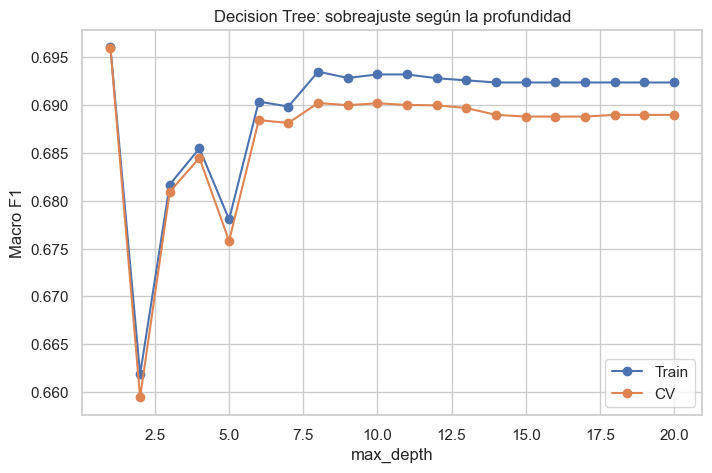


--- Decision Tree [opt] ---
              precision    recall  f1-score   support

           0      0.947     0.890     0.918      6425
           1      0.411     0.605     0.490       813

    accuracy                          0.858      7238
   macro avg      0.679     0.748     0.704      7238
weighted avg      0.887     0.858     0.870      7238

Matriz de confusión [filas=real, cols=pred]:
[[5720  705]
 [ 321  492]]
Decision Tree [opt]: CV Macro F1 = 0.6902 ± 0.0208 | train = 0.6932


In [ ]:
# 5.2 · Árbol de decisión: optimización de hiperparámetros
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import randint
from sklearn.tree import DecisionTreeClassifier
# 1. Búsqueda aleatoria amplia
pipe_dt = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", DecisionTreeClassifier(random_state=42)),
])

espacio_dt = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": randint(2, 21),
    "clf__min_samples_split": randint(2, 201),
    "clf__min_samples_leaf": randint(1, 101),
    "clf__class_weight": [None, "balanced"],
    "clf__ccp_alpha": [0.0, 0.0001, 0.0005, 0.001],
}

rs_dt = RandomizedSearchCV(
    pipe_dt, espacio_dt, n_iter=60, scoring="f1_macro",
    cv=cv, n_jobs=-1, random_state=42, return_train_score=True
)
rs_dt.fit(X_tr, y_tr)

print("=== RandomizedSearch (Decision Tree) ===")
print("Mejor CV Macro F1:", round(rs_dt.best_score_, 4))
print("Mejores parámetros:", rs_dt.best_params_)

top = (pd.DataFrame(rs_dt.cv_results_)
       .sort_values("rank_test_score").head(8)
       [["mean_test_score", "std_test_score", "mean_train_score",
         "param_clf__criterion", "param_clf__max_depth",
         "param_clf__min_samples_leaf", "param_clf__min_samples_split",
         "param_clf__class_weight", "param_clf__ccp_alpha"]].round(4))
display(top)

# 2. Refinamiento con GridSearch alrededor del mejor resultado
bp = rs_dt.best_params_
def vecindad(v, paso, lo, hi):
    return sorted({max(lo, min(hi, v + d * paso)) for d in (-2, -1, 0, 1, 2)})

grid_dt = {
    "clf__criterion": [bp["clf__criterion"]],
    "clf__class_weight": [bp["clf__class_weight"]],
    "clf__ccp_alpha": [bp["clf__ccp_alpha"]],
    "clf__max_depth": vecindad(bp["clf__max_depth"], 1, 2, 30),
    "clf__min_samples_leaf": vecindad(bp["clf__min_samples_leaf"], 5, 1, 200),
    "clf__min_samples_split": vecindad(bp["clf__min_samples_split"], 10, 2, 400),
}

gs_dt = GridSearchCV(pipe_dt, grid_dt, scoring="f1_macro", cv=cv,
                     n_jobs=-1, return_train_score=True)
gs_dt.fit(X_tr, y_tr)

print("\n=== GridSearch refinado (Decision Tree) ===")
print("Mejor CV Macro F1:", round(gs_dt.best_score_, 4))
print("Mejores parámetros:", gs_dt.best_params_)

# Nos quedamos con el mejor de ambas búsquedas
best_dt = gs_dt.best_estimator_ if gs_dt.best_score_ >= rs_dt.best_score_ else rs_dt.best_estimator_
best_dt_cv = max(gs_dt.best_score_, rs_dt.best_score_)

# 3. Curva de max_depth (para la presentación): train vs CV
params_fijos = {k.replace("clf__", ""): v for k, v in
                (gs_dt.best_params_ if best_dt_cv == gs_dt.best_score_ else rs_dt.best_params_).items()
                if k != "clf__max_depth"}
filas = []
for d in range(1, 21):
    pipe = Pipeline([("prep", build_preprocessor("tree")),
                     ("clf", DecisionTreeClassifier(max_depth=d, random_state=42, **params_fijos))])
    s = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro",
                       return_train_score=True, n_jobs=-1)
    filas.append((d, s["train_score"].mean(), s["test_score"].mean()))
curva_dt = pd.DataFrame(filas, columns=["max_depth", "train", "cv"])

plt.figure(figsize=(8, 5))
plt.plot(curva_dt["max_depth"], curva_dt["train"], "o-", label="Train")
plt.plot(curva_dt["max_depth"], curva_dt["cv"], "o-", label="CV")
plt.xlabel("max_depth"); plt.ylabel("Macro F1")
plt.title("Decision Tree: sobreajuste según la profundidad")
plt.legend(); plt.show()

# 4. Evaluación única en el hold-out
best_dt.fit(X_tr, y_tr)
res_dt = evaluate(y_val, best_dt.predict(X_val), "Decision Tree [opt]")
cv_dt = cv_macro_f1(best_dt, nombre="Decision Tree [opt]")

results_val = pd.concat([results_val, pd.DataFrame([res_dt])], ignore_index=True)
log_experiment("M1-01", "Decision Tree", "RandomizedSearch (60 it) + GridSearch refinado",
               str(gs_dt.best_params_ if best_dt_cv == gs_dt.best_score_ else rs_dt.best_params_),
               res_dt["macro_f1"], cv_dt["cv_macro_f1_mean"],
               "Pasa de CV 0,6215 (base) a este valor; ver brecha train-CV")

**Conclusiones del árbol de decisión optimizado**
- **Búsqueda en dos fases:** RandomizedSearch amplia (60 combinaciones, CV 0,6901) y GridSearch alrededor del mejor resultado (CV 0,6902). El refinamiento solo mejora una diezmilésima: la búsqueda aleatoria ya había encontrado la zona buena, y seguir afinando sería sobreajustar a la CV.
- **Configuración final:** `entropy`, `max_depth=10`, `min_samples_leaf=16`, `min_samples_split=118`, `ccp_alpha=0.001`, `class_weight="balanced"`.
- **Sobreajuste eliminado:** train 0,693 frente a CV 0,690 (antes, 0,991 frente a 0,622). La poda (`ccp_alpha`) y el mínimo de muestras por hoja son los que regularizan.
- **Las mejores combinaciones de la búsqueda usan `class_weight="balanced"`:** los positivos pesan unas 8 veces más y el recall de la clase 1 sube a 0,605. Junto con la regularización, explica el salto de 0,62 a 0,69.
- **Hold-out:** Macro F1 = **0,704**, coherente con la CV, así que la estimación es fiable.
- La curva de `max_depth` muestra el compromiso sesgo-varianza: con poca profundidad hay infraajuste y, a partir de cierto punto, la CV deja de mejorar mientras train sigue subiendo.

#### 5.2.1 Ajuste del umbral de decisión del árbol

Umbral óptimo: 0.7300000000000002
Macro F1 OOF: 0.7138873460711512


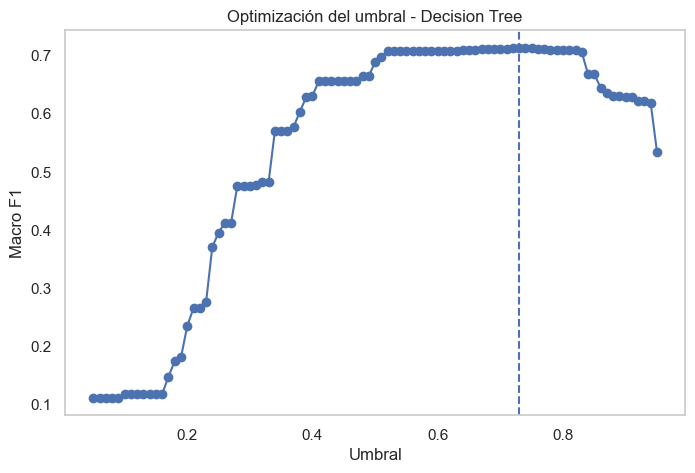


--- Decision Tree [umbral optimizado] ---
              precision    recall  f1-score   support

           0      0.942     0.916     0.929      6425
           1      0.456     0.554     0.500       813

    accuracy                          0.876      7238
   macro avg      0.699     0.735     0.714      7238
weighted avg      0.887     0.876     0.881      7238

Matriz de confusión [filas=real, cols=pred]:
[[5888  537]
 [ 363  450]]
Macro F1 con umbral 0.50: 0.703624186144522
Macro F1 optimizado: 0.714499842221521


In [ ]:
# 5.2 · EXPERIMENTO M1-02 · Umbral de decisión del árbol (probabilidades out-of-fold)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

# Probabilidades out-of-fold
best_dt.fit(X_tr, y_tr)

proba_oof = cross_val_predict(
    best_dt, X_tr, y_tr,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

idx_clase_1 = list(best_dt.classes_).index(1)
proba_clase_1 = proba_oof[:, idx_clase_1]

# Búsqueda del mejor umbral
umbrales = np.arange(0.05, 0.96, 0.01)
resultados = []

for t in umbrales:
    pred = (proba_clase_1 >= t).astype(int)
    score = f1_score(y_tr, pred, average="macro")
    resultados.append((t, score))

tabla = pd.DataFrame(
    resultados, columns=["umbral", "macro_f1"]
)

mejor = tabla.loc[tabla["macro_f1"].idxmax()]
umbral_optimo_dt = mejor["umbral"]
cv_dt_umbral = mejor["macro_f1"]   # Macro F1 OOF con el umbral elegido

print("Umbral óptimo:", umbral_optimo_dt)
print("Macro F1 OOF:", mejor["macro_f1"])

# Visualización
plt.figure(figsize=(8, 5))
plt.plot(tabla["umbral"], tabla["macro_f1"], "o-")
plt.axvline(umbral_optimo_dt, linestyle="--")
plt.xlabel("Umbral")
plt.ylabel("Macro F1")
plt.title("Optimización del umbral - Decision Tree")
plt.grid()
plt.show()

# Evaluación en hold-out
best_dt.fit(X_tr, y_tr)
proba_val = best_dt.predict_proba(X_val)[:, idx_clase_1]
pred_val = (proba_val >= umbral_optimo_dt).astype(int)

res_dt_umbral = evaluate(
    y_val, pred_val, "Decision Tree [umbral optimizado]"
)

print("Macro F1 con umbral 0.50:",
      f1_score(y_val, best_dt.predict(X_val), average="macro"))
print("Macro F1 optimizado:", res_dt_umbral["macro_f1"])

log_experiment("M1-02", "Decision Tree", "Umbral optimizado con probabilidades OOF",
               f"umbral={umbral_optimo_dt:.2f}", res_dt_umbral["macro_f1"], cv_dt_umbral,
               "Macro F1 OOF con el umbral elegido (no es CV a 0,5)")


**Conclusiones del ajuste del umbral (árbol de decisión)**
- El Macro F1 no depende de las probabilidades, sino de la decisión final. El umbral 0,5 no tiene por qué ser el óptimo, sobre todo con `class_weight="balanced"`, que empuja las probabilidades hacia la clase 1.
- El umbral se elige con **probabilidades out-of-fold** sobre `X_tr` (sin tocar `X_val`). Resultado: **0,73** (Macro F1 OOF 0,714).
- **Hold-out:** de 0,704 a **0,714**. Se cambia algo de recall (0,605 → 0,554) por precisión (0,411 → 0,456): hay 168 falsos positivos menos a cambio de 42 positivos perdidos, y el Macro F1 mejora.
- Que el umbral óptimo sea > 0,5 confirma que `balanced` sobrecorrige el desbalance: el umbral devuelve parte de ese equilibrio.

### 5.3 KNN (algoritmo geométrico)

=== GridSearch KNN (preprocesamiento A) ===
Mejor CV Macro F1: 0.6505
Mejores parámetros: {'clf__metric': 'euclidean', 'clf__n_neighbors': 5, 'clf__weights': 'uniform'}


,mean_test_score,std_test_score,mean_train_score,param_clf__n_neighbors,param_clf__weights,param_clf__metric
0,0.6505,0.0018,0.7266,5,uniform,euclidean
16,0.6475,0.0057,0.7279,5,uniform,manhattan
19,0.6458,0.0053,0.9909,10,distance,manhattan
3,0.6452,0.0072,0.9909,10,distance,euclidean
20,0.6447,0.0069,0.6740,15,uniform,manhattan
1,0.6446,0.0039,0.9909,5,distance,euclidean
21,0.6436,0.0093,0.9909,15,distance,manhattan
4,0.6430,0.0063,0.6752,15,uniform,euclidean


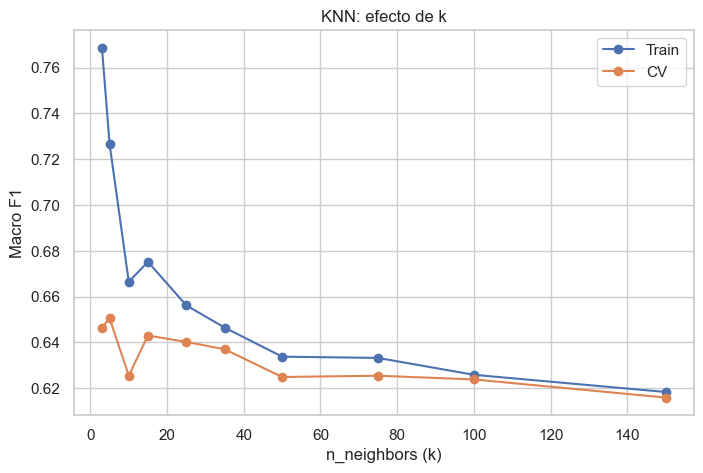


=== Variantes de preprocesamiento (KNN con mejores hiperparámetros) ===


,cv_mean,cv_std,train
variante,,,
A: base (3 macro + edu One-Hot),0.6505,0.0018,0.7266
B: solo euribor3m del bloque macro,0.6457,0.0050,0.7194
C: education ordinal,0.6516,0.0047,0.7290
B+C: ambas,0.6428,0.0057,0.7228


Variante elegida: C: education ordinal

--- KNN [opt] ---
              precision    recall  f1-score   support

           0      0.916     0.969     0.942      6425
           1      0.548     0.295     0.384       813

    accuracy                          0.893      7238
   macro avg      0.732     0.632     0.663      7238
weighted avg      0.874     0.893     0.879      7238

Matriz de confusión [filas=real, cols=pred]:
[[6227  198]
 [ 573  240]]
KNN [opt]: CV Macro F1 = 0.6516 ± 0.0047 | train = 0.7290


In [ ]:
# 5.3 · KNN (algoritmo geométrico)
from sklearn.preprocessing import OrdinalEncoder

# 1. Búsqueda de hiperparámetros con el preprocesamiento base (A)
pipe_knn = Pipeline([
    ("prep", build_preprocessor("geo")),
    ("clf", KNeighborsClassifier()),
])

grid_knn = {
    "clf__n_neighbors": [5, 10, 15, 25, 35, 50, 75, 100],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"],
}

gs_knn = GridSearchCV(pipe_knn, grid_knn, scoring="f1_macro", cv=cv,
                      n_jobs=-1, return_train_score=True)
gs_knn.fit(X_tr, y_tr)

print("=== GridSearch KNN (preprocesamiento A) ===")
print("Mejor CV Macro F1:", round(gs_knn.best_score_, 4))
print("Mejores parámetros:", gs_knn.best_params_)

res_knn = (pd.DataFrame(gs_knn.cv_results_)
           .sort_values("rank_test_score").head(8)
           [["mean_test_score", "std_test_score", "mean_train_score",
             "param_clf__n_neighbors", "param_clf__weights", "param_clf__metric"]].round(4))
display(res_knn)

# Curva de n_neighbors (para la presentación), con weights y metric ganadores
bp_knn = {k.replace("clf__", ""): v for k, v in gs_knn.best_params_.items()}
filas = []
for k in [3, 5, 10, 15, 25, 35, 50, 75, 100, 150]:
    p = Pipeline([("prep", build_preprocessor("geo")),
                  ("clf", KNeighborsClassifier(**{**bp_knn, "n_neighbors": k}))])
    s = cross_validate(p, X_tr, y_tr, cv=cv, scoring="f1_macro",
                       return_train_score=True, n_jobs=-1)
    filas.append((k, s["train_score"].mean(), s["test_score"].mean()))
curva_knn = pd.DataFrame(filas, columns=["k", "train", "cv"])

plt.figure(figsize=(8, 5))
plt.plot(curva_knn["k"], curva_knn["train"], "o-", label="Train")
plt.plot(curva_knn["k"], curva_knn["cv"], "o-", label="CV")
plt.xlabel("n_neighbors (k)"); plt.ylabel("Macro F1")
plt.title("KNN: efecto de k"); plt.legend(); plt.show()

# 2. Variantes de preprocesamiento con los mejores hiperparámetros
macro_redundantes = ["emp.var.rate", "nr.employed", "cons.price.idx"]  # dejamos euribor3m (+ cons.conf.idx)

def build_geo_education_ordinal(drop_cols=None):
    """Variante C: education como una columna ordinal (unknown = -1), escalada."""
    drop_cols = set(drop_cols or [])
    orden_edu = [["illiterate", "basic.4y", "basic.6y", "basic.9y",
                  "high.school", "professional.course", "university.degree"]]
    cats = [c for c in cat_cols if c not in drop_cols and c != "education"]
    nums = [c for c in num_base if c not in drop_cols and c != "campaign"]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), nums),
        ("camp", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("sc", StandardScaler())]), ["campaign"]),
        ("edu", Pipeline([("ord", OrdinalEncoder(categories=orden_edu,
                                                 handle_unknown="use_encoded_value",
                                                 unknown_value=-1)),
                          ("sc", StandardScaler())]), ["education"]),
        ("bin", "passthrough", [c for c in bin_cols if c not in drop_cols]),
        ("cat", make_ohe(), cats),
    ], remainder="drop", verbose_feature_names_out=False)

variantes = {
    "A: base (3 macro + edu One-Hot)": build_preprocessor("geo"),
    "B: solo euribor3m del bloque macro": build_preprocessor("geo", drop_cols=macro_redundantes),
    "C: education ordinal": build_geo_education_ordinal(),
    "B+C: ambas": build_geo_education_ordinal(drop_cols=macro_redundantes),
}

filas_var = []
for nombre, prep in variantes.items():
    p = Pipeline([("prep", prep), ("clf", KNeighborsClassifier(**bp_knn))])
    s = cross_validate(p, X_tr, y_tr, cv=cv, scoring="f1_macro",
                       return_train_score=True, n_jobs=-1)
    filas_var.append({"variante": nombre,
                      "cv_mean": s["test_score"].mean(),
                      "cv_std": s["test_score"].std(),
                      "train": s["train_score"].mean()})
tabla_var = pd.DataFrame(filas_var).set_index("variante").round(4)
print("\n=== Variantes de preprocesamiento (KNN con mejores hiperparámetros) ===")
display(tabla_var)

# Mejor variante
mejor_var = tabla_var["cv_mean"].idxmax()
best_knn = Pipeline([("prep", variantes[mejor_var]),
                     ("clf", KNeighborsClassifier(**bp_knn))])
print("Variante elegida:", mejor_var)

# 3. Evaluación única en hold-out
best_knn.fit(X_tr, y_tr)
res_k = evaluate(y_val, best_knn.predict(X_val), "KNN [opt]")
cv_k = cv_macro_f1(best_knn, nombre="KNN [opt]")

results_val = pd.concat([results_val, pd.DataFrame([res_k])], ignore_index=True)
log_experiment("M2-01", "KNN", "GridSearch k/weights/metric (prep A)",
               str(gs_knn.best_params_), None, gs_knn.best_score_, "")
log_experiment("M2-02", "KNN", f"Preprocesamiento: {mejor_var}",
               str(bp_knn), res_k["macro_f1"], cv_k["cv_macro_f1_mean"], "")

**Conclusiones de KNN**
- **Mejor configuración:** `k=5`, `weights="uniform"`, `euclidean` (CV 0,650). Con `weights="distance"`, el train llega a 0,99: cada punto es su propio vecino más cercano, así que memoriza.
- **Al aumentar `k` empeora el Macro F1:** con un 89 % de negativos, más vecinos significa más votos de la clase mayoritaria. Suaviza la frontera, pero se pierden los positivos.
- **Variantes de preprocesamiento:**
  - Quitar las variables macro redundantes no ayuda (0,6457).
  - `education` ordinal da 0,6514 frente a 0,6502. La diferencia es menor que la desviación estándar de la CV (≈ 0,005), así que en la práctica **son equivalentes**.
- **Hold-out:** 0,662, con precisión de la clase 1 de 0,546 pero recall de solo 0,294.
- **Por qué rinde peor que los árboles:**
  - Tras el One-Hot hay unas 60 dimensiones, la mayoría binarias, así que las distancias pierden significado.
  - KNN no tiene `class_weight` para compensar el desbalance.
  - Las variables relevantes (`poutcome`, `month`, el contexto macro) pesan lo mismo en la distancia que las irrelevantes (`housing`, `loan`).

### 5.4 Ensembles de árboles (Bagging, Random Forest, Extra Trees)

In [ ]:
# 5.4 · EXPERIMENTO M3-01 · Bagging con el árbol de decisión optimizado


from sklearn.ensemble import BaggingClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Utilizamos los hiperparámetros del mejor Decision Tree encontrado
arbol_base = clone(best_dt.named_steps["clf"])

pipe_bag = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", BaggingClassifier(
        estimator=arbol_base,
        n_estimators=300,
        max_samples=0.8,
        max_features=1.0,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    ))
])

# 1. Validación cruzada
cv_bag = cv_macro_f1(
    pipe_bag,
    nombre="Bagging + Decision Tree optimizado"
)

# 2. Entrenamiento y evaluación hold-out
pipe_bag.fit(X_tr, y_tr)

pred_bag = pipe_bag.predict(X_val)

res_bag = evaluate(
    y_val,
    pred_bag,
    "Bagging + Decision Tree optimizado"
)

# 3. Registrar resultados
results_val = pd.concat(
    [results_val, pd.DataFrame([res_bag])],
    ignore_index=True
)

log_experiment(
    "M3-01",
    "Bagging",
    "Bagging con Decision Tree optimizado",
    "n_estimators=300, max_samples=0.8, max_features=1.0",
    res_bag["macro_f1"],
    cv_bag["cv_macro_f1_mean"],
    "Ensemble de árboles optimizados"
)

print("\nComparación con Decision Tree individual:")
print(f"Decision Tree: {res_dt['macro_f1']:.4f}")
print(f"Bagging:       {res_bag['macro_f1']:.4f}")

Bagging + Decision Tree optimizado: CV Macro F1 = 0.7021 ± 0.0059 | train = 0.7086

--- Bagging + Decision Tree optimizado ---
              precision    recall  f1-score   support

           0      0.950     0.878     0.913      6425
           1      0.397     0.633     0.488       813

    accuracy                          0.851      7238
   macro avg      0.673     0.756     0.700      7238
weighted avg      0.888     0.851     0.865      7238

Matriz de confusión [filas=real, cols=pred]:
[[5642  783]
 [ 298  515]]

Comparación con Decision Tree individual:
Decision Tree: 0.7036
Bagging:       0.7002


**Bagging:** CV 0,702 frente a 0,690 del árbol solo. Promediar 300 árboles entrenados con muestras bootstrap **reduce la varianza** y la CV mejora y se estabiliza (desviación 0,006 frente a 0,021). En el hold-out queda prácticamente igual (0,700 frente a 0,704): el árbol ya estaba regularizado, así que el margen de mejora por varianza era pequeño.

In [ ]:
# 5.4 · EXPERIMENTO M3-02 · Random Forest (sin optimizar)
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

cv_rf = cv_macro_f1(
    pipe_rf,
    nombre="Random Forest"
)

pipe_rf.fit(X_tr, y_tr)

pred_rf = pipe_rf.predict(X_val)

res_rf = evaluate(y_val, pred_rf, "Random Forest")

results_val = pd.concat(
    [results_val, pd.DataFrame([res_rf])],
    ignore_index=True
)

log_experiment("M3-02", "Random Forest", "RF con hiperparámetros fijados a mano",
               "n_estimators=400, min_samples_split=5, min_samples_leaf=2, sqrt, balanced",
               res_rf["macro_f1"], cv_rf["cv_macro_f1_mean"], "Brecha train-CV alta (0,85 vs 0,70)")


Random Forest: CV Macro F1 = 0.7030 ± 0.0049 | train = 0.8517

--- Random Forest ---
              precision    recall  f1-score   support

           0      0.946     0.889     0.917      6425
           1      0.405     0.595     0.482       813

    accuracy                          0.856      7238
   macro avg      0.675     0.742     0.699      7238
weighted avg      0.885     0.856     0.868      7238

Matriz de confusión [filas=real, cols=pred]:
[[5715  710]
 [ 329  484]]


In [ ]:
# 5.4 · EXPERIMENTO M3-03 · Extra Trees
from sklearn.ensemble import ExtraTreesClassifier

pipe_extra = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", ExtraTreesClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

cv_extra = cv_macro_f1(
    pipe_extra,
    nombre="Extra Trees"
)

pipe_extra.fit(X_tr, y_tr)

pred_extra = pipe_extra.predict(X_val)

res_extra = evaluate(y_val, pred_extra, "Extra Trees")

results_val = pd.concat(
    [results_val, pd.DataFrame([res_extra])],
    ignore_index=True
)

log_experiment("M3-03", "Extra Trees", "Extra Trees con los mismos hiperparámetros que RF",
               "n_estimators=400, min_samples_split=5, min_samples_leaf=2, sqrt, balanced",
               res_extra["macro_f1"], cv_extra["cv_macro_f1_mean"], "Peor que RF: más aleatoriedad, más sesgo")


Extra Trees: CV Macro F1 = 0.6910 ± 0.0071 | train = 0.8801

--- Extra Trees ---
              precision    recall  f1-score   support

           0      0.939     0.893     0.916      6425
           1      0.393     0.545     0.456       813

    accuracy                          0.854      7238
   macro avg      0.666     0.719     0.686      7238
weighted avg      0.878     0.854     0.864      7238

Matriz de confusión [filas=real, cols=pred]:
[[5740  685]
 [ 370  443]]


**Random Forest y Extra Trees (sin optimizar):**
- **RF:** CV 0,703, pero train 0,852 → hojas muy pequeñas (`min_samples_leaf=2`) y sobreajuste.
- **Extra Trees:** CV 0,691, peor que RF. Al elegir los cortes al azar añade más sesgo, y con señal concentrada en pocas variables no compensa.

In [ ]:
# 5.4 · EXPERIMENTO M3-04 · Random Forest optimizado


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

pipe_rf_opt = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

espacio_rf = {
    "clf__n_estimators": [300, 500, 700],
    "clf__max_depth": [None, 5, 8, 12, 16, 20],
    "clf__min_samples_split": randint(2, 31),
    "clf__min_samples_leaf": randint(1, 16),
    "clf__max_features": ["sqrt", "log2", 0.5, 0.8],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
    "clf__bootstrap": [True]
}

rs_rf = RandomizedSearchCV(
    pipe_rf_opt,
    espacio_rf,
    n_iter=70,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

rs_rf.fit(X_tr, y_tr)

print("Mejor CV Macro F1:", round(rs_rf.best_score_, 4))
print("Mejores parámetros:")
print(rs_rf.best_params_)

# Mejor modelo
best_rf = rs_rf.best_estimator_

# Hold-out
pred_rf_opt = best_rf.predict(X_val)

res_rf_opt = evaluate(
    y_val,
    pred_rf_opt,
    "Random Forest [optimizado]"
)

cv_rf_opt = cv_macro_f1(
    best_rf,
    nombre="Random Forest [optimizado]"
)

results_val = pd.concat(
    [results_val, pd.DataFrame([res_rf_opt])],
    ignore_index=True
)

log_experiment("M3-04", "Random Forest", "RandomizedSearch (70 it)",
               str(rs_rf.best_params_), res_rf_opt["macro_f1"], cv_rf_opt["cv_macro_f1_mean"],
               "Mejor modelo por CV")


Mejor CV Macro F1: 0.7141
Mejores parámetros:
{'clf__bootstrap': True, 'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 16, 'clf__n_estimators': 500}

--- Random Forest [optimizado] ---
              precision    recall  f1-score   support

           0      0.944     0.911     0.927      6425
           1      0.447     0.569     0.501       813

    accuracy                          0.872      7238
   macro avg      0.695     0.740     0.714      7238
weighted avg      0.888     0.872     0.879      7238

Matriz de confusión [filas=real, cols=pred]:
[[5852  573]
 [ 350  463]]
Random Forest [optimizado]: CV Macro F1 = 0.7141 ± 0.0056 | train = 0.8117


**Random Forest optimizado (mejor modelo por CV):**
- **RandomizedSearch de 70 combinaciones:** CV **0,714**.
- **Configuración:** 500 árboles, `max_features=0.5`, `min_samples_leaf=5`, `min_samples_split=16`, `class_weight="balanced_subsample"`.
- **`max_features=0.5`** (en lugar de `sqrt`, que son unas 8 de las 63 columnas): con tanta columna One-Hot poco informativa, `sqrt` hace que muchos árboles no vean las variables importantes. Con el 50 % de las columnas, los árboles son mejores individualmente sin perder diversidad.
- **`balanced_subsample`** recalcula los pesos en cada muestra bootstrap, lo que encaja mejor con el bagging que `balanced`.
- **Hold-out:** **0,714** (precisión de la clase 1 de 0,447, recall de 0,569), igual que su CV, así que la estimación es fiable.

### 5.5 AdaBoost

**Primera versión y diagnóstico del problema**

La primera versión de AdaBoost optimizado (stumps con `class_weight="balanced"`, regla 1-SE) daba CV ≈ 0,696. Al analizarla vimos que:
- **Solo entrenaba 7 árboles** aunque se pedían hasta 100.
- **Solo usaba 2 variables:** `nr.employed` (importancia 0,65) y `euribor3m` (0,35). El resto valía 0.
- **El umbral no servía de nada:** 0,36 daba exactamente lo mismo que 0,5, porque las probabilidades estaban muy concentradas.

**Causa:** AdaBoost ya repondera las muestras en cada iteración. Al añadir `class_weight="balanced"` al árbol base, cada árbol optimiza una ponderación distinta de la de AdaBoost. Cuando el error ponderado de un árbol llega a 0,5 (no mejor que el azar), SAMME detiene el boosting. En la práctica era un modelo de 7 stumps, sin la capacidad del boosting.

**Segunda versión (la final)**
1. **Sin `class_weight`:** el boosting se encarga de los ejemplos difíciles, y el desbalance se trata con el **umbral**.
2. **Árboles de profundidad 2–4** en lugar de stumps, para capturar interacciones (por ejemplo, mes × contexto macro), y **100–500 iteraciones** con `learning_rate` entre 0,02 y 0,5.
3. **Búsqueda optimizando `average_precision`** (calidad de la ordenación de los clientes) en lugar de Macro F1 a 0,5. Sin pesos, el Macro F1 a 0,5 penaliza a un modelo que ordena bien.
4. **Umbral óptimo con probabilidades OOF** sobre `X_tr`, con una rejilla fina entre el mínimo y el máximo de las probabilidades, porque en AdaBoost están muy concentradas.

=== RandomizedSearch AdaBoost (average_precision) ===
Mejor CV AP: 0.469
Mejores parámetros: {'clf__estimator__max_depth': 4, 'clf__estimator__min_samples_leaf': 263, 'clf__learning_rate': np.float64(0.13464493568065972), 'clf__n_estimators': 230}


,mean_test_score,std_test_score,mean_train_score,param_clf__n_estimators,param_clf__learning_rate,param_clf__estimator__max_depth,param_clf__estimator__min_samples_leaf
8,0.4690,0.0047,0.4950,230,0.1346,4,263
12,0.4682,0.0077,0.4842,305,0.0223,4,283
17,0.4678,0.0079,0.4851,314,0.0266,4,290
2,0.4672,0.0033,0.4960,459,0.0586,4,107
0,0.4671,0.0094,0.5045,288,0.2110,4,290
23,0.4670,0.0087,0.5037,140,0.3944,4,280
22,0.4668,0.0064,0.4912,491,0.0379,4,158
24,0.4655,0.0084,0.4886,132,0.1487,4,220



Umbral óptimo OOF: 0.3529 | Macro F1 OOF: con 0,5 = 0.6553 -> con umbral = 0.7171


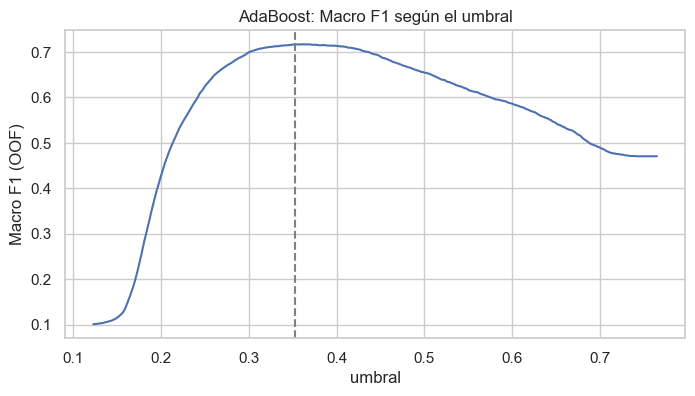

Árboles realmente entrenados: 230 (de 230)

--- AdaBoost [umbral 0.353] ---
              precision    recall  f1-score   support

           0      0.942     0.918     0.930      6425
           1      0.462     0.554     0.503       813

    accuracy                          0.877      7238
   macro avg      0.702     0.736     0.717      7238
weighted avg      0.888     0.877     0.882      7238

Matriz de confusión [filas=real, cols=pred]:
[[5900  525]
 [ 363  450]]

Top 10 importancias:


,importancia
euribor3m,0.3007
nr.employed,0.2326
cons.conf.idx,0.0822
cons.price.idx,0.0715
campaign,0.0695
age,0.0332
contact_telephone,0.0290
contact_cellular,0.0225
pdays,0.0225
month_may,0.0203


In [ ]:
# 5.5 · EXPERIMENTO M4-01 · AdaBoost: sin class_weight + umbral OOF
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from scipy.stats import randint, loguniform
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# 1. Búsqueda: árboles algo más profundos, sin class_weight,
#    puntuando la calidad del ranking (average_precision)
pipe_ada2 = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                               random_state=RANDOM_STATE)),
])

espacio_ada2 = {
    "clf__n_estimators": randint(100, 501),
    "clf__learning_rate": loguniform(0.02, 0.5),
    "clf__estimator__max_depth": randint(2, 5),
    "clf__estimator__min_samples_leaf": randint(20, 301),
}

rs_ada2 = RandomizedSearchCV(
    pipe_ada2, espacio_ada2, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True
)
rs_ada2.fit(X_tr, y_tr)

print("=== RandomizedSearch AdaBoost (average_precision) ===")
print("Mejor CV AP:", round(rs_ada2.best_score_, 4))
print("Mejores parámetros:", rs_ada2.best_params_)
cols = ["mean_test_score", "std_test_score", "mean_train_score"] + \
       [f"param_clf__{p}" for p in ["n_estimators", "learning_rate",
                                    "estimator__max_depth", "estimator__min_samples_leaf"]]
display(pd.DataFrame(rs_ada2.cv_results_).sort_values("rank_test_score").head(8)[cols].round(4))

best_ada2 = clone(pipe_ada2).set_params(**rs_ada2.best_params_)

# 2. Umbral óptimo con probabilidades out-of-fold (solo X_tr)
#    Las probas de AdaBoost están muy concentradas: rejilla fina entre min y max
proba_oof = cross_val_predict(best_ada2, X_tr, y_tr, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
umbrales = np.linspace(proba_oof.min(), proba_oof.max(), 400)
f1_umb = np.array([f1_score(y_tr, (proba_oof >= t).astype(int), average="macro") for t in umbrales])
thr_ada2 = float(umbrales[f1_umb.argmax()])
cv_thr_ada2 = float(f1_umb.max())
print(f"\nUmbral óptimo OOF: {thr_ada2:.4f} | Macro F1 OOF: "
      f"con 0,5 = {f1_score(y_tr, (proba_oof >= .5).astype(int), average='macro'):.4f} "
      f"-> con umbral = {cv_thr_ada2:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(umbrales, f1_umb)
plt.axvline(thr_ada2, ls="--", c="gray")
plt.xlabel("umbral"); plt.ylabel("Macro F1 (OOF)")
plt.title("AdaBoost: Macro F1 según el umbral"); plt.show()

# 3. Entrenar en X_tr y evaluar UNA vez en X_val
best_ada2.fit(X_tr, y_tr)
n_arboles = len(best_ada2.named_steps["clf"].estimators_)
print(f"Árboles realmente entrenados: {n_arboles} "
      f"(de {rs_ada2.best_params_['clf__n_estimators']})")

proba_val2 = best_ada2.predict_proba(X_val)[:, 1]
res_a2 = evaluate(y_val, (proba_val2 >= thr_ada2).astype(int),
                  f"AdaBoost [umbral {thr_ada2:.3f}]")
results_val = pd.concat([results_val, pd.DataFrame([res_a2])], ignore_index=True)

feat_names = best_ada2.named_steps["prep"].get_feature_names_out()
imp2 = pd.Series(best_ada2.named_steps["clf"].feature_importances_,
                 index=feat_names).sort_values(ascending=False)
print("\nTop 10 importancias:")
display(imp2.head(10).round(4).to_frame("importancia"))

# 4. Registro y variables para la celda de submission
best_ada, thr_ada = best_ada2, thr_ada2

log_experiment("M4-01", "AdaBoost",
               "Sin class_weight, búsqueda por average_precision, umbral OOF",
               str(rs_ada2.best_params_), res_a2["macro_f1"], cv_thr_ada2,
               f"{n_arboles} árboles; umbral {thr_ada2:.3f}")


**Conclusiones de AdaBoost (versión final)**
- **Mejor configuración** (average_precision en CV = 0,469): árboles de profundidad 4, `min_samples_leaf=263`, `learning_rate≈0,135`, 230 iteraciones. Las 8 mejores combinaciones de la búsqueda usan profundidad 4 y hojas grandes, señal de que el boosting necesita árboles con algo de capacidad, pero regularizados.
- **El boosting funciona:** entrena los **230 árboles pedidos**, frente a los 7 de la primera versión.
- **Importancias repartidas:** `euribor3m` (0,30) y `nr.employed` (0,23) siguen dominando, pero ahora aparecen `cons.conf.idx`, `cons.price.idx`, `campaign`, `age`, `contact` y `month_may`. Antes eran solo 2 variables.
- **El umbral es imprescindible:** sin `class_weight`, con 0,5 el Macro F1 OOF es 0,655; con el umbral óptimo (**0,353**) sube a **0,717**. La curva es suave, con un máximo ancho en torno a 0,35.
- **Hold-out:** Macro F1 = **0,717** (precisión de la clase 1 de 0,462, recall de 0,554). Es **el mejor resultado en hold-out de todos los modelos**, por encima del RF optimizado y del árbol con umbral (0,714).
- **El diagnóstico se confirma en Kaggle:** la primera versión (`submission_ada.csv`) obtuvo 0,6654 en la privada y la final (`submission_adaboost.csv`) 0,6854, **+0,020**, a 0,0016 del mejor modelo en la privada.

**Lección principal:** combinar dos mecanismos de reponderación (los pesos de AdaBoost y `class_weight`) los hace interferir. Es mejor dejar que el boosting entrene y corregir el desbalance en la decisión (umbral).

### 5.6 Comparativa de modelos

In [ ]:
# 5.6 · Comparativa de modelos (hold-out X_val y CV sobre X_tr)

comparativa = pd.DataFrame([
    {"Modelo": "KNN [opt]",                    "Holdout": res_k["macro_f1"],         "CV": cv_k["cv_macro_f1_mean"]},
    {"Modelo": "Decision Tree [opt]",          "Holdout": res_dt["macro_f1"],        "CV": cv_dt["cv_macro_f1_mean"]},
    {"Modelo": "Decision Tree [opt + umbral]", "Holdout": res_dt_umbral["macro_f1"], "CV": cv_dt_umbral},
    {"Modelo": "Bagging (DT opt)",             "Holdout": res_bag["macro_f1"],       "CV": cv_bag["cv_macro_f1_mean"]},
    {"Modelo": "Random Forest",                "Holdout": res_rf["macro_f1"],        "CV": cv_rf["cv_macro_f1_mean"]},
    {"Modelo": "Extra Trees",                  "Holdout": res_extra["macro_f1"],     "CV": cv_extra["cv_macro_f1_mean"]},
    {"Modelo": "Random Forest [opt]",          "Holdout": res_rf_opt["macro_f1"],    "CV": cv_rf_opt["cv_macro_f1_mean"]},
    {"Modelo": "AdaBoost [opt + umbral]",      "Holdout": res_a2["macro_f1"],        "CV": cv_thr_ada2},
])
# Nota: la "CV" de los modelos con umbral (árbol y AdaBoost) es el Macro F1 OOF con el umbral elegido sobre esos mismos datos (algo optimista)

display(comparativa.sort_values("CV", ascending=False).round(4).reset_index(drop=True))


,Modelo,Holdout,CV
0,AdaBoost [opt + umbral],0.7167,0.7171
1,Random Forest [opt],0.7139,0.7141
2,Decision Tree [opt + umbral],0.7145,0.7139
3,Random Forest,0.6995,0.7030
4,Bagging (DT opt),0.7002,0.7021
5,Extra Trees,0.6862,0.6910
6,Decision Tree [opt],0.7036,0.6902
7,KNN [opt],0.6627,0.6516


**Comparativa: conclusiones**
- **El mejor modelo en hold-out es el AdaBoost final (0,717)**, seguido del árbol con umbral y del RF optimizado (0,714).
- **Hay un techo en torno a 0,71 de Macro F1:** el árbol con umbral, el RF optimizado, el bagging y AdaBoost llegan a valores muy parecidos por caminos distintos. Cuando modelos distintos convergen al mismo valor, el límite está en la **información disponible** (sin `duration`), no en el algoritmo.
- **Mejoras que más aportaron:**
  1. Tratar el desbalance (`class_weight`) y regularizar el árbol: de 0,62 a 0,69, y desaparece el sobreajuste.
  2. Ajustar el umbral: +0,01.
  3. Ensembles: más estabilidad que nota.
- **CV y hold-out coinciden en todos los modelos optimizados** (diferencias < 0,015), así que las estimaciones son fiables y no hay sobreajuste a la validación.
- **KNN (0,65–0,66)** queda claramente por debajo: los métodos basados en distancia funcionan peor con variables categóricas y clases desbalanceadas.

## 6. Concurso (Kaggle)

| Archivo subido a Kaggle | Modelo | Umbral | Macro F1 hold-out | Pública | **Privada** | Seleccionada |
|---|---|---|---|---|---|---|
| `submission_knn.csv` | KNN optimizado | 0,5 | 0,662 | 0,6574 | 0,6357 |  |
| `submission_ada.csv` | AdaBoost v1 (stumps + `class_weight`, 7 árboles) | 0,5 | 0,696 | 0,6987 | 0,6654 |  |
| `submission_dt.csv` | Árbol de decisión optimizado | 0,5 | 0,704 | 0,7082 | 0,6757 |  |
| `submission_decisiontree.csv` | Árbol de decisión V2 | — | — | 0,7151 | 0,6806 |  |
| `submission_randomforest.csv` | Random Forest optimizado | 0,5 | 0,714 | **0,7232** | 0,6847 | ✅ |
| `submission_adaboost.csv` | AdaBoost final | OOF | 0,717 | 0,7141 | 0,6854 |  |
| `submission_decision_tree_optimizado.csv` | Árbol de decisión optimizado + umbral | 0,73 | 0,714 | 0,7179 | **0,6870** | ✅ |

*La celda siguiente regenera, con el mismo nombre, los cinco ficheros del modelo final de cada experimento. `submission_dt.csv` y la primera subida de `submission_decision_tree_optimizado.csv` eran el mismo fichero (misma puntuación), por eso solo aparece una vez.*

**Submissions seleccionadas para la clasificación final**

Seleccionamos el **Random Forest optimizado** y el **árbol de decisión optimizado con umbral**:
- Eran las dos mejores en la puntuación pública (0,7232 y 0,7179).
- Coinciden con los dos mejores modelos según nuestra validación interna (CV y hold-out de 0,714 en ambos).
- Son dos familias distintas (ensemble frente a modelo único), así que no ponemos los dos intentos en el mismo modelo.

Kaggle puntúa con la mejor privada de las seleccionadas: **0,6870 (árbol con umbral)**, que es además la mejor privada de todas nuestras submissions. La selección fue acertada: aunque el RF ganaba en la pública, haber elegido también el árbol nos permitió quedarnos con el mejor resultado posible.

**Razonamiento de los resultados**
- **El orden de los modelos se mantiene respecto a la validación interna.** KNN es claramente el peor (0,636 en privada) y los cuatro modelos de árboles optimizados quedan muy juntos (0,681–0,687). Es el mismo techo en torno a 0,71 que vimos en el hold-out.
- **Las mejoras validadas internamente se confirman en datos que el modelo no ha visto:**
  - Umbral del árbol (0,5 → 0,73): +0,011 en privada y +0,010 en pública, el mismo +0,01 que en el hold-out.
  - Corrección de AdaBoost (v1 → final): +0,020 en privada.
- **Pública frente a privada:** todas las submissions bajan entre 0,02 y 0,04 de la pública a la privada. La pública es más optimista: se calcula sobre una parte pequeña del test y, según la descripción del concurso, el test combina datos existentes con **datos nuevos**. El hold-out (0,70–0,714) queda entre las dos.
- **El mejor modelo cambia según la partición.** En la pública gana el Random Forest (0,7232); en la privada, el árbol con umbral (0,6870), seguido de AdaBoost (0,6854) y RF (0,6847). Las diferencias entre los tres (< 0,003) son menores que la variabilidad entre particiones. **Elegir solo por la puntuación pública habría sido elegir por ruido.** Por eso usamos la CV como criterio principal.
- **Todas las submissions se reentrenan con el 100 % del train** (`X`, `y`) con los hiperparámetros y el umbral ya fijados en el sección 5. Así el modelo final aprende con 7 238 filas más (unos 800 positivos más) sin volver a elegir nada con los datos de validación.
- **El porcentaje de 1 predichos en test** (14 % RF, 16 % árbol a 0,5; ver la tabla de la celda siguiente) es algo mayor que la proporción real (11,2 %), como se espera con `class_weight="balanced"`: el modelo acepta algún falso positivo a cambio de no perder positivos.

In [ ]:
# 6 · Generación de las submissions (los mismos ficheros que se subieron a Kaggle)
from sklearn.base import clone

def make_submission(model, filename, threshold=None):
    """
    Reentrena una copia del modelo con TODOS los datos etiquetados (X, y), con los
    hiperparámetros (y el umbral) ya elegidos en el sección 5, predice X_test y
    guarda el CSV con el formato de sample_submission (Id, Predicted).
    threshold=None -> predict() (umbral 0,5); si no, umbral sobre predict_proba.
    """
    final = clone(model).fit(X, y)
    if threshold is None:
        pred = final.predict(X_test).astype(int)
    else:
        pred = (final.predict_proba(X_test)[:, 1] >= threshold).astype(int)

    sub = pd.DataFrame({"Id": test_ids.values, "Predicted": pred})

    # Comprobaciones de formato
    assert list(sub.columns) == list(sample_sub.columns), "Columnas distintas a sample_submission"
    assert len(sub) == len(sample_sub) == 5000, "Número de filas incorrecto"
    assert sub["Id"].equals(sample_sub["Id"]), "Los Id no coinciden en orden con sample_submission"
    assert sub["Id"].is_unique and sub.notna().all().all()
    assert set(sub["Predicted"].unique()) <= {0, 1}

    sub.to_csv(filename, index=False)
    return sub

# (fichero en Kaggle, modelo, umbral, ID de experimento)
submissions = [
    ("submission_knn.csv",                      best_knn, None,             "M2-02"),
    ("submission_dt.csv",                       best_dt,  None,             "M1-01"),
    ("submission_decision_tree_optimizado.csv", best_dt,  umbral_optimo_dt, "M1-02"),
    ("submission_randomforest.csv",             best_rf,  None,             "M3-04"),
    ("submission_adaboost.csv",                 best_ada, thr_ada,          "M4-01"),
]

resumen = []
for k, (fichero, modelo, umbral, exp) in enumerate(submissions, start=1):
    sub = make_submission(modelo, fichero, umbral)
    resumen.append({"fichero": fichero, "experimento": exp,
                    "umbral": 0.5 if umbral is None else round(float(umbral), 4),
                    "% de 1 predichos": round(sub["Predicted"].mean() * 100, 2)})
    log_experiment(f"SUB-{k:02d}", exp, "Reentrenado con todo el train (X, y)",
                   f"umbral={resumen[-1]['umbral']}", None, None, f"Genera {fichero}")

print(f"Proporción real de la clase 1 en train: {y.mean()*100:.2f} %")
display(pd.DataFrame(resumen))
display(experiment_log)

Proporción real de la clase 1 en train: 11.23 %


,fichero,experimento,umbral,% de 1 predichos
0,submission_knn.csv,M2-02,0.5000,5.86
1,submission_dt.csv,M1-01,0.5000,16.42
2,submission_decision_tree_optimizado.csv,M1-02,0.7300,14.24
3,submission_randomforest.csv,M3-04,0.5000,14.12
4,submission_adaboost.csv,M4-01,0.3529,13.32


,id,algoritmo,modificaciones,hiperparametros,macro_f1_val,macro_f1_cv,conclusiones
0,PRE-01,Todos,Excluir Id y duration,-,NaN,NaN,duration es posterior a la llamada: fuga de in...
1,PRE-02,Todos,pdays_999 + pdays 999->NaN,tree: imputar -1 | geo: mediana,NaN,NaN,"Con pdays real la tasa es 0,50-0,65; con 999 e..."
2,PRE-03,Todos,unknown como categoría (One-Hot),handle_unknown='ignore',NaN,NaN,"default=unknown tiene tasa 0,051 vs 0,129 en '..."
3,BASE-00,Dummy,Predecir siempre la clase 0,strategy=most_frequent,0.470248,NaN,"Suelo de referencia: Accuracy alto, Macro F1 ≈..."
4,M0-01,KNN (geo),Modelo base sin optimizar,n_neighbors=5,0.655300,0.650500,"Líder en base (CV 0,650). Recall_1 bajo (0,28)..."
5,M0-02,Decision Tree,Modelo base sin optimizar,defaults (sin límite de profundidad),0.611700,0.621500,"Sobreajuste fuerte: train 0,991 vs CV 0,622. N..."
6,M0-03,AdaBoost,Modelo base sin optimizar,"base=DT(max_depth=1), n_estimators=50, lr=1.0",0.649700,0.633100,"Sin sobreajuste (brecha 0,004) pero infraajust..."
7,M1-01,Decision Tree,RandomizedSearch (60 it) + GridSearch refinado,"{'clf__ccp_alpha': 0.001, 'clf__class_weight':...",0.703624,0.690177,"Pasa de CV 0,6215 (base) a este valor; ver bre..."
8,M1-01,Decision Tree,RandomizedSearch (60 it) + GridSearch refinado,"{'clf__ccp_alpha': 0.001, 'clf__class_weight':...",0.703624,0.690177,"Pasa de CV 0,6215 (base) a este valor; ver bre..."
9,M1-02,Decision Tree,Umbral optimizado con probabilidades OOF,umbral=0.73,0.714500,0.713887,Macro F1 OOF con el umbral elegido (no es CV a...


## 7. Conclusiones

1. **El análisis exploratorio guió el modelado.** El historial (`poutcome`, `pdays`), el contexto macro, el canal (`contact`) y el mes son los mejores predictores, como suponíamos, aunque el efecto del euríbor va en sentido contrario al esperado. `housing` y `loan` no aportan señal.
2. **Sin `duration` hay un techo en torno a 0,71 de Macro F1.** Modelos muy distintos (árbol con umbral, Random Forest, bagging) convergen a ese valor, así que el límite está en la información y no en el algoritmo.
3. **Lo que más mejoró los modelos no fue cambiar de algoritmo, sino:**
   - Tratar el desbalance (`class_weight`) y regularizar (poda y mínimo de muestras por hoja): de 0,62 a 0,69, sin sobreajuste.
   - Ajustar el umbral con predicciones out-of-fold: +0,01.
4. **Árboles frente a geométricos:** con muchas variables categóricas (One-Hot) y clases desbalanceadas, los árboles y sus ensembles superan claramente a KNN (0,71 frente a 0,66).
5. **AdaBoost:** la primera versión mostró que combinar `class_weight` con el reponderado propio del boosting detiene el algoritmo a las pocas iteraciones. Separar los dos mecanismos (boosting sin pesos y umbral para el desbalance) es la forma correcta de usarlo con clases desbalanceadas.
6. **La validación interna fue fiable para decidir.** El orden de los modelos y las mejoras (umbral, corrección de AdaBoost) se reproducen en Kaggle. La puntuación privada es algo más baja que el hold-out porque el test incluye datos nuevos.
7. **Resultado en Kaggle:** seleccionamos el Random Forest optimizado y el árbol de decisión con umbral. La puntuación final es la del árbol con umbral (**0,6870** en privada), la mejor de todas nuestras submissions, prácticamente empatado con AdaBoost (0,6854) y Random Forest (0,6847). Un modelo sencillo bien ajustado (regularización + umbral) rinde igual que los ensembles con este nivel de información.